# Now we are interested in moving towards more complex NNs

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# let's read names.txt
words = open('makemore_files/names.txt', 'r').read().splitlines()

In [3]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
# names.txt statistics
print(f'we have {len(words)} names in the list')
print(f'the shortest name has {min(len(w) for w in words)} characters')
print(f'the longest name has {max(len(w) for w in words)} characters')

we have 32033 names in the list
the shortest name has 2 characters
the longest name has 15 characters


In [5]:
# build some useful lists and dictionaries

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [6]:
# build the dataset


block_size = 3 # context length: how many previous characters do we use to predict the next one
def build_dataset(words,block_size):
    X, Y = [],[]
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words)) # 80% of data for training
n2 = int(0.9*len(words)) # 10% more for validation

Xtr, Ytr = build_dataset(words[:n1], block_size=block_size) # 80% of data for training
Xdev, Ydev = build_dataset(words[n1:n2], block_size=block_size) # 10% more for validation
Xte, Yte = build_dataset(words[n2:], block_size=block_size) # final 10% for testing


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [7]:
# MLP revisited

g = torch.Generator().manual_seed(2147483647) # reproducibility

block_size = 3
embed_dims = 10 
inner_neurons = 200
n_inputs = block_size * embed_dims

# our parameters that need tuning
C = torch.randn((vocab_size,embed_dims), generator=g) # generate our look up table, represent each character as a 2D vector
W1 = torch.randn((n_inputs,inner_neurons), generator=g) # hidden layer with 100 neurons. (modified by changing inner_neurons number)
b1 = torch.randn(inner_neurons, generator=g) # 100 biases for 100 neurons. (modified by changing inner_neurons number)
W2 = torch.randn((inner_neurons,27), generator=g) # output layer with 27 neurons
b2 = torch.randn(vocab_size, generator=g) # 27 biases for 27 neurons
parameters = [C, W1, b1, W2, b2] # input X is not a parameter (leaf node), but the lookup table C that built the embeddings is.
for p in parameters:
    p.requires_grad = True # tell pytorch to track gradients because default it False

# -- initializations
# separately, let's also look at how to determine the step size/learning rate
# above we tried 0.1 and see that it works pretty well, but is this the best option?
# separate checks find that 1 leads to large oscillations but 0.001 leads to very slow optimization, so let's look at step sizes between 1 and 0.001
lre = torch.linspace(-3, 0, 1000) # typically this is investigated using a learning rate exponent, taking 10**lre, we see that -3 indicates 0.001. Stepping linearly doesn't really make sens. Why? Not sure
lrs = 10**lre

lri, lossi, lrei = [], [], []
step = 0
stepi = []

In [8]:
# MLP

n_steps = 200000

# while step < n_steps:
for i in range(n_steps):
    # Note optimizing on the full dataset of X.shape[0] = 228146 points will take too long.
    # It is MUCH more practical to optimize the dataset on mini-batches. Mini-batches are randomized subsets in each iteration to decrease compute time while learning from the entire set
    ix = torch.randint(0, Xtr.shape[0], (32,)) # generates a random set of 32 indices (int) in Xtr to create our minibatch. 32 is chosen arbitrarily
    Xb, Yb = Xtr[ix], Ytr[ix]

    #forward pass
    emb = C[Xb] # create our embedding by looking up from table C, minibatched
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors (practice this!)
    hpreact = embcat @ W1 + b1 # hidden layer pre activation
    h = torch.tanh(hpreact) # hidden layer output, tanh taken
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # minibatched

    # backward pass
    # initialize and clean any leftover gradients. Recall gradients are accumulated so cleaning for each loop is important
    for p in parameters:
        p.grad = None # same as setting to 0 in pytorch
    loss.backward()
    lr = 0.1 if i < 100000 else 0.01 # automated learning rate decay
    for p in parameters:
        p.data += -lr * p.grad # update parameters using gradient descen

    if i % 10000 == 0: # print every 10000 steps
        print(f'{i:7d}/{n_steps:7d}: {loss.item():.4f}')
    stepi.append(step+1)
    step += 1
    lossi.append(loss.log10().item())

print(f'Final loss: {loss.item()}')
print(f'Total steps taken: {i}')

      0/ 200000: 22.8883
  10000/ 200000: 2.9193
  20000/ 200000: 2.5631
  30000/ 200000: 2.4780
  40000/ 200000: 2.6546
  50000/ 200000: 2.2241
  60000/ 200000: 2.0253
  70000/ 200000: 1.9964
  80000/ 200000: 2.0802
  90000/ 200000: 2.5310
 100000/ 200000: 2.4477
 110000/ 200000: 1.8954
 120000/ 200000: 2.1590
 130000/ 200000: 2.0007
 140000/ 200000: 2.2320
 150000/ 200000: 2.4582
 160000/ 200000: 2.2205
 170000/ 200000: 1.5743
 180000/ 200000: 1.7449
 190000/ 200000: 2.5289
Final loss: 1.9694876670837402
Total steps taken: 199999


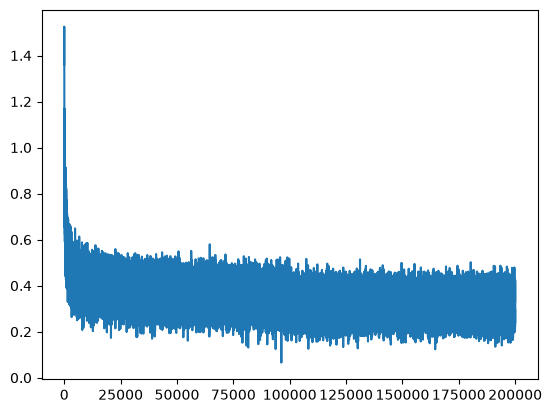

In [16]:
plt.plot(stepi, lossi)

In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
# we want to make sure we reduce the bookkeeping in the function below. Makes evaluation more data efficient

def split_loss(split):
    x, y = {'train': (Xtr, Ytr),
            'val': (Xdev, Ydev),
            'test': (Xte, Yte)}[split]
    emb = C[x] # (N, block_size, embed_dims)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size*embed_dims)
    hpreact = embcat @ W1 + b1 # hidden layer pre activation
    h = torch.tanh(hpreact) # hidden layer output, tanh taken
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, y)

    print(split, loss.item())

split_loss('train')
split_loss('val')
# split_loss('test')

train 2.1263327598571777
val 2.169752836227417


In [ ]:
# sample from the model

g = torch.Generator().manual_seed(2147483647+10) # why +10 though?

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with ...
    while True:
        emb = C[torch.tensor([context])] # (1, block_size, d)
        h = torch.tanh(emb.view(1,-1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item() # remember, multinomial generates a sample based on the probabilities output by the model.
                                                                         # this is how we use the model to generate new outputs.
                                                                         # here we start blank, but we could potentially start with [0,0,1] to have a name that starts with 'a'
        #shift context window and track the samples
        context = context[1:] + [ix] 
        out.append(ix)
        # end when we come to the end of a word, identified by '.'
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

carlah.
ambril.
khi.
mili.
tatyanna.
sane.
rahnen.
delynn.
jareei.
nermari.
chaiir.
kaleigh.
ham.
join.
quint.
sulin.
alian.
quinathon.
jarysi.
jace.


In [ ]:
# Let's look at the loss of the first step of our random initialization
import numpy as np
print(f'step 1 loss of random initialization: {10**lossi[0]}') # reminder we recorded the log of loss not the loss for plotting
print()
print('With 27 possible letters+start/end, we expect the worst prediction to be all 27 outputs are equally likely')
print(-torch.tensor(1/27.0).log()) # reminder the NLL is our model's loss
print('So at initialization, we have no reason to believe one character is more likely than another (equal probability),\n so the loss is supposed to take on the above value')
print()
print('Immediately we see that the initial error is much higher than the worst prediction.')
print('This is because our initialization was not done well')

step 1 loss of random initialization: 22.88827490114496

With 27 possible letters+start/end, we expect the worst prediction to be all 27 outputs are equally likely
tensor(3.2958)
So at initialization, we have no reason to believe one character is more likely than another (equal probability),
 so the loss is supposed to take on the above value

Immediately we see that the initial error is much higher than the worst prediction.
This is because our initialization was not done well


In [ ]:
# 4 dimensional example of the issue
logits = torch.tensor([0.0,0.0,0.0,0.0])
# logits = torch.randn(4)
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log()
probs, loss

(tensor([0.2500, 0.2500, 0.2500, 0.2500]), tensor(1.3863))

So now let's see where things go wrong in our example

In [ ]:
# MLP revisited
g = torch.Generator().manual_seed(2147483647) # reproducibility

block_size = 3
embed_dims = 10 
inner_neurons = 200
n_inputs = block_size * embed_dims

# our parameters that need tuning
C = torch.randn((vocab_size,embed_dims),    generator=g)
# activation comes from W1, b1
W1 = torch.randn((n_inputs,inner_neurons),  generator=g) * (5/3) / (n_inputs**0.5) # Kaiming initialization instead of scaling with magic number
# b1 = torch.randn(inner_neurons,             generator=g) * 0.01 # similar to W1, but no longer needed with batch normalization, 'replaced' with bnbias below
# W1 = torch.randn((n_inputs,inner_neurons),  generator=g) * 0.2 # reduce these values to minimize activations that end up at gradient=0 regions
# b1 = torch.randn(inner_neurons,             generator=g) * 0.01 # similar to W1
# logits are generated from the below weights and biases W2, b2
# when initializing, we actually want all the logits to be close to zero for a uniform distribution
W2 = torch.randn((inner_neurons,27),        generator=g) * 0.01 # to properly initialize a uniform logits, we want to scale the randomly generated weights down
b2 = torch.randn(vocab_size,                generator=g) * 0 # similarly, we don't actually want any biases to skew the initialization so we set this to zero
# W2 = torch.randn((inner_neurons,27),        generator=g) * 0.01 # to properly initialize a uniform logits, we want to scale the randomly generated weights down
# b2 = torch.randn(vocab_size,                generator=g) * 0 # similarly, we don't actually want any biases to skew the initialization so we set this to zero
# so for W2 and b2, we can technically start with torch.zeros, 

# batch normalization gain and bias
bngain = torch.ones((1, inner_neurons)) # start at no gain, i.e. multiply by 1
bnbias = torch.zeros((1, inner_neurons)) # start at no gain, i.e. add 0
# and add these to the list of parameters

# to track the batch norm mean and std as part of the training to avoid running a separate calculation
bnmean_running = torch.zeros((1, inner_neurons)) # initialize at zero because the mean of a unit gaussian is zero
bnstd_running = torch.ones((1, inner_neurons)) # initialize at one because the std of a unit gaussian is one

parameters = [C, W1, b1, W2, b2, bngain, bnbias] # input X is not a parameter (leaf node), but the lookup table C that built the embeddings is.
for p in parameters:
    p.requires_grad = True # tell pytorch to track gradients because default it False

# -- initializations
# separately, let's also look at how to determine the step size/learning rate
# above we tried 0.1 and see that it works pretty well, but is this the best option?
# separate checks find that 1 leads to large oscillations but 0.001 leads to very slow optimization, so let's look at step sizes between 1 and 0.001
lre = torch.linspace(-3, 0, 1000) # typically this is investigated using a learning rate exponent, taking 10**lre, we see that -3 indicates 0.001. Stepping linearly doesn't really make sens. Why? Not sure
lrs = 10**lre

lri, lossi, lrei = [], [], []
step = 0
stepi = []

In [ ]:
# MLP

n_steps = 200000

# while step < n_steps:
for i in range(n_steps):
    # Note optimizing on the full dataset of X.shape[0] = 228146 points will take too long.
    # It is MUCH more practical to optimize the dataset on mini-batches. Mini-batches are randomized subsets in each iteration to decrease compute time while learning from the entire set
    ix = torch.randint(0, Xtr.shape[0], (32,)) # generates a random set of 32 indices (int) in Xtr to create our minibatch. 32 is chosen arbitrarily
    Xb, Yb = Xtr[ix], Ytr[ix]

    #forward pass
    emb = C[Xb] # create our embedding by looking up from table C, minibatched
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors (practice this!)
    hpreact = embcat @ W1 #+ b1 # hidden layer pre activation, remove b1 tensor because it is redundant with the subtraction below. bnbias will capture the bias instead
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    # # batch normalization
    hpreact = bngain * (hpreact- bnmeani) / bnstdi - bnbias # hidden layer pre activation, normalized to unit gaussian, with bias and gain
    # one thing to note is that b1 is redundant with this normalization as it cancels out in hpreact-bnmeani, so we can remove the b1 bias tensor

    # keep track of the batch norm mean and std across the entire set instead of just the minibatch. This is done on the side, no backprop required
    # use of janky running average works just fine
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    h = torch.tanh(hpreact) # hidden layer output, tanh taken
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # minibatched

    # backward pass
    # initialize and clean any leftover gradients. Recall gradients are accumulated so cleaning for each loop is important
    for p in parameters:
        p.grad = None # same as setting to 0 in pytorch
    loss.backward()
    lr = 0.1 if i < 100000 else 0.01 # automated learning rate decay
    for p in parameters:
        p.data += -lr * p.grad # update parameters using gradient descen

    if i % 10000 == 0: # print every 10000 steps
        print(f'{i:7d}/{n_steps:7d}: {loss.item():.4f}')
    stepi.append(step+1)
    step += 1
    lossi.append(loss.log10().item())

    # break # to see the loss at the first iteration

print(f'Final loss: {loss.item()}')
print(f'Total steps taken: {i}')

      0/ 200000: 3.2752
  10000/ 200000: 2.3220
  20000/ 200000: 2.0591
  30000/ 200000: 2.5428
  40000/ 200000: 1.9751
  50000/ 200000: 1.8509
  60000/ 200000: 2.2259
  70000/ 200000: 2.2741
  80000/ 200000: 2.1954
  90000/ 200000: 2.3084
 100000/ 200000: 2.1191
 110000/ 200000: 2.2411
 120000/ 200000: 1.8633
 130000/ 200000: 2.0343
 140000/ 200000: 1.9505
 150000/ 200000: 2.0346
 160000/ 200000: 2.1287
 170000/ 200000: 2.4280
 180000/ 200000: 1.9571
 190000/ 200000: 2.1757
Final loss: 1.9785268306732178
Total steps taken: 199999


In [ ]:
# calibrate the batch norm at the end of training
# note that the mean and std should be calculated across the entire set instead of each minibatch so it should be done separately.
# because doing things separately is extra work, folks typically embed this into the training loop by tracking the running average across all mini batches

# separate calibration, absolute correct way, but bnmean_running and bnstd_running is close to this and does not need an extra calibration
# with torch.no_grad():
#     # pass the training set through
#     emb = C[Xtr]
#     embcat = emb.view(emb.shape[0], -1)
#     hpreact = embcat @ W1 + b1
#     # measure the mean/std over the entire training set
#     bnmean = hpreact.mean(0, keepdim=True)
#     bnstd = hpreact.std(0, keepdim=True)

In [135]:
@torch.no_grad() # this decorator disables gradient tracking
# we want to make sure we reduce the bookkeeping in the function below. Makes evaluation more data efficient

def split_loss_bn(split):
    x, y = {'train': (Xtr, Ytr),
            'val': (Xdev, Ydev),
            'test': (Xte, Yte)}[split]
    emb = C[x] # (N, block_size, embed_dims)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size*embed_dims)
    hpreact = embcat @ W1 + b1 # hidden layer pre activation
    # hpreact = bngain * (hpreact- bnmean) / bnstd - bnbias # hidden layer pre activation, normalized to unit gaussian, with bias and gain
    hpreact = bngain * (hpreact- bnmean_running) / bnstd_running - bnbias # hidden layer pre activation, normalized to unit gaussian, with bias and gain
    h = torch.tanh(hpreact) # hidden layer output, tanh taken
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, y)

    print(split, loss.item())

split_loss_bn('train')
split_loss_bn('val')
# split_loss_bn('test')

train 2.0690793991088867
val 2.1085643768310547


In [ ]:
h

tensor([[ 3.2422e-01, -5.7706e-01, -9.8845e-01,  ...,  8.6352e-01,
          7.4965e-01, -9.9818e-01],
        [ 9.9781e-01, -1.1226e-01, -9.8353e-01,  ..., -2.4945e-01,
          5.6685e-01,  9.2538e-01],
        [-1.4269e-01, -9.3848e-05,  3.3792e-02,  ..., -4.2454e-01,
          4.2702e-01, -5.4335e-02],
        ...,
        [ 9.2071e-01, -9.9853e-01, -9.5138e-01,  ...,  9.8425e-01,
         -1.0000e+00, -9.9342e-01],
        [ 9.9063e-01, -9.9896e-01,  2.4006e-01,  ..., -7.3082e-01,
         -3.6082e-01, -9.0156e-01],
        [ 2.2147e-01, -1.0615e-01, -3.4903e-01,  ..., -6.0749e-01,
         -9.9963e-01,  8.6926e-01]], grad_fn=<TanhBackward0>)

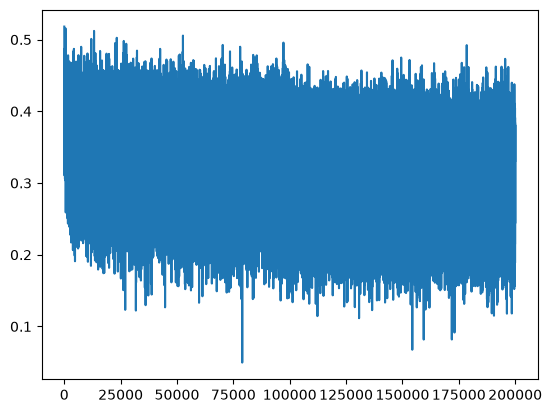

In [92]:
plt.plot(stepi, lossi)

In [ ]:
# using tanh as an activation function is also something to think about.
# given the random initialization, we see that many values in h takes either 1 or -1, which have gradient of 0 (flat). t=1,-1, (1-t**2)=0
# this means that for those connections, there is no gradient being propagated through that connection.
# in the worst case, all connections that propogate through one neuron could have 0 gradient, leading to a dead neuron.
# Obviously, a dead neuron is a neuron that does not "learn", i.e. backpropagation does not go through that neuron because of the 0 tanh gradient

# this is not a problem exclusive to tanh. Other activation functions have the same issue

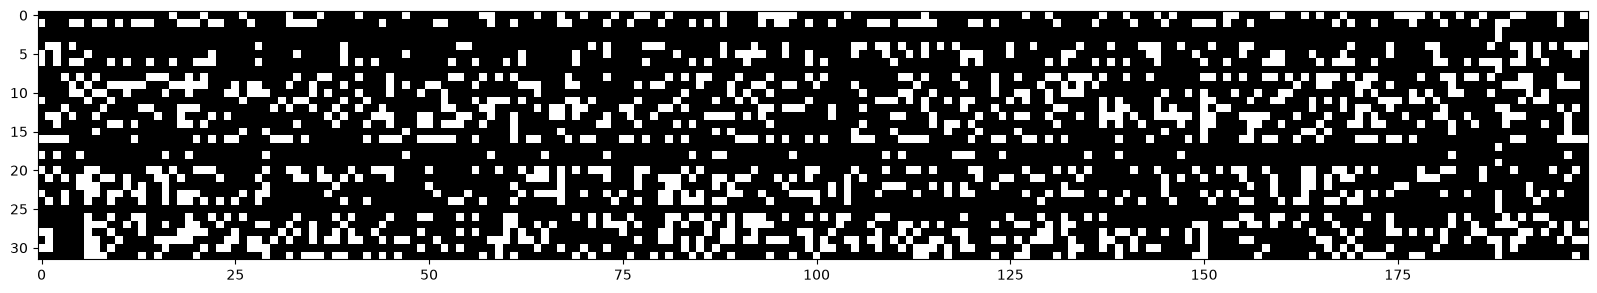

In [93]:
# visualizing h=tanh() values
plt.figure(figsize=(20,10))
plt.imshow(h.abs()>0.99, cmap='gray', interpolation='nearest')
# column of all white would be a dead neuron

(array([1068.,  231.,  148.,  113.,  107.,   77.,   72.,   53.,   48.,
          66.,   57.,   44.,   51.,   72.,   79.,   62.,   77.,   70.,
          64.,   86.,   85.,  124.,   82.,  112.,  106.,  173.,  125.,
         114.,  107.,  107.,   73.,   65.,   57.,   72.,   54.,   41.,
          43.,   68.,   50.,   48.,   67.,   83.,   59.,   61.,   72.,
          93.,  141.,  162.,  223., 1088.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

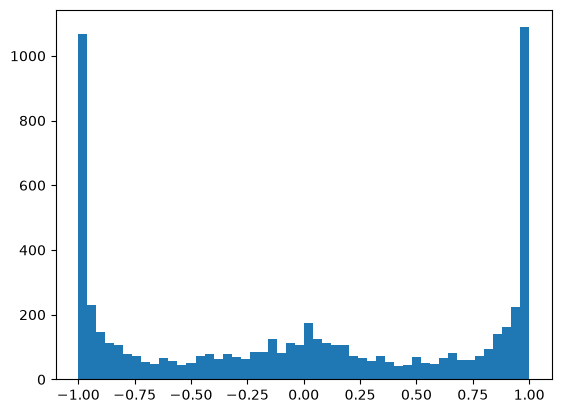

In [94]:
plt.hist(h.view(-1).tolist(), 50)

(array([1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        6.000e+00, 6.000e+00, 2.000e+00, 1.300e+01, 9.000e+00, 1.900e+01,
        2.100e+01, 3.300e+01, 3.900e+01, 6.100e+01, 7.600e+01, 9.700e+01,
        1.530e+02, 1.860e+02, 1.850e+02, 2.370e+02, 2.780e+02, 3.220e+02,
        3.510e+02, 6.490e+02, 1.147e+03, 4.580e+02, 3.500e+02, 3.400e+02,
        2.730e+02, 2.350e+02, 2.090e+02, 1.480e+02, 1.220e+02, 1.110e+02,
        8.000e+01, 3.800e+01, 5.000e+01, 3.900e+01, 1.700e+01, 1.300e+01,
        8.000e+00, 8.000e+00, 3.000e+00, 3.000e+00, 2.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([-11.06093788, -10.6412636 , -10.22158932,  -9.80191504,
         -9.38224075,  -8.96256647,  -8.54289219,  -8.12321791,
         -7.70354362,  -7.28386934,  -6.86419506,  -6.44452078,
         -6.0248465 ,  -5.60517221,  -5.18549793,  -4.76582365,
         -4.34614937,  -3.92647509,  -3.5068008 ,  -3.08712652,
         -2.66745224,  -2.24777796,  -1.82810368,  -1.40

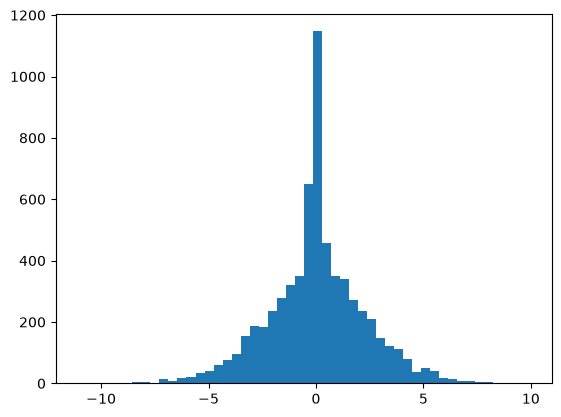

In [95]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [ ]:
# loss log

# original
# train 2.1263327598571777
# val 2.169752836227417

# fix softmax 
# train 
# val 

# fix activation tanh too saturated at init (magic numbers)
# train 2.0374510288238525
# val 2.105424165725708

# use semi-principled 'kaiming init' instead of magic numbers
# train 2.039862871170044
# val 2.108046531677246

# add batch normalization to hidden layer
# train 2.0680201053619385
# val 2.108870029449463

So we have been multiplying our initialization with magic numbers. Obviously nobody really does this by hand, and there are actually principled was of setting these scales. Once such scale 

tensor(-0.0103) tensor(0.9987)
tensor(-0.0004) tensor(0.9955)


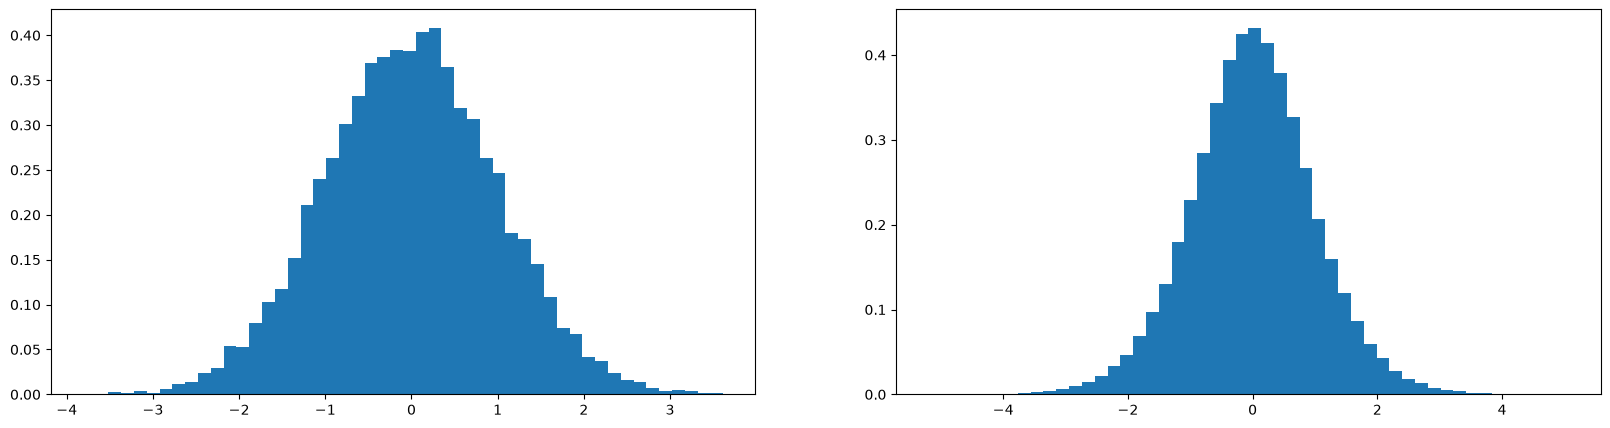

In [116]:
x = torch.randn(1000,10)
w = torch.randn(10, 200) / 10**0.5
y = x @ w
print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize=(20,5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density = True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True)
plt.show()

# we see that the std of y is much larger than x, this is a problem.
# we ideally want most of our NN to have similar activations, so x and y should adopt the shape of a unit gaussian (similar mean and std).
    # We can scale our initial weights w to bring y.std() closer to x.std()
        # one way to do this is by dividing our weights by the sqrt of the number of input elements of w, in this case, divide by 10^0.5
    # ML research have also looked into this, such as in Kaiming He et al.'s publication where they looked at the scaling for NNs (specifically ReLU/PReLU squashing)
        # we note this because the Kaiming normalization is one of the most popular way of scaling weights in modern NNs
        # note that this work also multiplies the weights by a gain. For a NN with tanh squashing, they found 5/3 to be a decent general gain
        # Kaiming initialization is implemented in pytorch

# In practice, normalizing our weights by *gain/n^0.5 is a pretty good way to start and works well with normal optimization algorithms


Precisely setting initializations is good but not too important now with modern optimization algorithms.

One such algorithm is batch normalization

In [120]:
hpreact.shape

torch.Size([32, 200])

In [ ]:
hpreact.mean(0, keepdim=True).shape

torch.Size([1, 200])

In [ ]:
hpreact = (hpreact- hpreact.mean(0, keepdim=True))/hpreact.std(0, keepdim=True)

Quick summary of things done/changes made to NN optimization

In [ ]:
# MLP revisited
g = torch.Generator().manual_seed(2147483647) # reproducibility

block_size = 3
embed_dims = 10 
inner_neurons = 200
n_inputs = block_size * embed_dims

# our parameters that need tuning
C = torch.randn((vocab_size,embed_dims),    generator=g)
# activation comes from W1, b1
W1 = torch.randn((n_inputs,inner_neurons),  generator=g) * (5/3) / (n_inputs**0.5) # Kaiming initialization instead of scaling with magic number
# b1 = torch.randn(inner_neurons,             generator=g) * 0.01 # similar to W1, but no longer needed with batch normalization, 'replaced' with bnbias below

# weights and biases for logits, initialized small to avoid 0 gradient backprop with tanh
W2 = torch.randn((inner_neurons,27),        generator=g) * 0.01 # to properly initialize a uniform logits, we want to scale the randomly generated weights down
b2 = torch.randn(vocab_size,                generator=g) * 0 # similarly, we don't actually want any biases to skew the initialization so we set this to zero
# so for W2 and b2, we can technically start with torch.zeros, 

# batch normalization parameters
bngain = torch.ones((1, inner_neurons)) # start at no gain, i.e. multiply by 1
bnbias = torch.zeros((1, inner_neurons)) # start at no gain, i.e. add 0

# track the batch norm mean and std as part of the training
# ------------------------------
bnmean_running = torch.zeros((1, inner_neurons)) # initialize at zero because the mean of a unit gaussian is zero
bnstd_running = torch.ones((1, inner_neurons)) # initialize at one because the std of a unit gaussian is one

parameters = [C, W1, b1, W2, b2, bngain, bnbias] # input X is not a parameter (leaf node), but the lookup table C that built the embeddings is.
for p in parameters:
    p.requires_grad = True # tell pytorch to track gradients because default it False

# -- initializations
lre = torch.linspace(-3, 0, 1000) # typically this is investigated using a learning rate exponent, taking 10**lre, we see that -3 indicates 0.001. Stepping linearly doesn't really make sens. Why? Not sure
lrs = 10**lre

lri, lossi, lrei = [], [], []
step = 0
stepi = []

In [ ]:
# MLP with softmax fix, kaiming init and batch norm

n_steps = 200000

# while step < n_steps:
for i in range(n_steps):
    # minibatch
    ix = torch.randint(0, Xtr.shape[0], (32,)) # generates a random set of 32 indices (int) in Xtr to create our minibatch. 32 is chosen arbitrarily
    Xb, Yb = Xtr[ix], Ytr[ix]

    #forward pass
    emb = C[Xb] # create our embedding by looking up from table C, minibatched
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors (practice this!)
    hpreact = embcat @ W1 # + b1 # hidden layer pre activation, 'replaced' by bnbias
    # batch normalization
    # ------------------------------
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact- bnmeani) / bnstdi - bnbias # hidden layer pre activation normalized to unit gaussian, with gain and bias
    # running average of batch norm mean and std across the entire set instead of just the minibatch. No backprop required
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # ------------------------------
    # non-linearity
    h = torch.tanh(hpreact) # hidden layer output, tanh taken
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # minibatched

    # backward pass
    # clean gradients
    for p in parameters:
        p.grad = None # same as setting to 0 in pytorch
    loss.backward()

    # update weights and biases
    lr = 0.1 if i < 100000 else 0.01 # automated learning rate decay
    for p in parameters:
        p.data += -lr * p.grad # update parameters using gradient descent

    # track stats
    if i % 10000 == 0: # print every 10000 steps
        print(f'{i:7d}/{n_steps:7d}: {loss.item():.4f}')
    step += 1
    stepi.append(i+1)
    lossi.append(loss.log10().item())

print(f'Final loss: {loss.item()}')
print(f'Total steps taken: {i+1}')

      0/ 200000: 3.2752
  10000/ 200000: 2.3220
  20000/ 200000: 2.0591
  30000/ 200000: 2.5428
  40000/ 200000: 1.9751
  50000/ 200000: 1.8509
  60000/ 200000: 2.2259
  70000/ 200000: 2.2741
  80000/ 200000: 2.1954
  90000/ 200000: 2.3084
 100000/ 200000: 2.1191
 110000/ 200000: 2.2411
 120000/ 200000: 1.8633
 130000/ 200000: 2.0343
 140000/ 200000: 1.9505
 150000/ 200000: 2.0346
 160000/ 200000: 2.1287
 170000/ 200000: 2.4280
 180000/ 200000: 1.9571
 190000/ 200000: 2.1757
Final loss: 1.9785268306732178
Total steps taken: 199999


In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
# we want to make sure we reduce the bookkeeping in the function below. Makes evaluation more data efficient

def split_loss_bn(split):
    x, y = {'train': (Xtr, Ytr),
            'val': (Xdev, Ydev),
            'test': (Xte, Yte)}[split]
    emb = C[x] # (N, block_size, embed_dims)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size*embed_dims)
    hpreact = embcat @ W1 + b1 # hidden layer pre activation
    # hpreact = bngain * (hpreact- bnmean) / bnstd - bnbias # hidden layer pre activation, normalized to unit gaussian, with bias and gain
    hpreact = bngain * (hpreact- bnmean_running) / bnstd_running - bnbias # hidden layer pre activation, normalized to unit gaussian, with bias and gain
    h = torch.tanh(hpreact) # hidden layer output, tanh taken
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, y)

    print(split, loss.item())

split_loss_bn('train')
split_loss_bn('val')
# split_loss_bn('test')

train 2.0690793991088867
val 2.1085643768310547


In [ ]:
# One pattern to remember, bias=False for layer right before batch normalization due to spurious subtraction shown above

# we can also add a small value to the batch norm denominator (bnstdi+eps) to avoid division by zero if bnstdi turns out to be zero
# the coefficient for adding new bnmeani and bnstdi to the running average is tuned by 'momentum' in pytorch.

# Overall, this notebook went through the initializations and normalizations that go into training a NN, and is in line with what's implemented in Pytorch.
# the initialization and normalization strategies help train a more stable NN by:
    # minimizing the number of dead connections (gradient = 0, no propagation) and hence dead neurons
    # more consistent distribution across NN layers

Bonus: Let's train a deeper network

In [143]:
class Linear:
    # initialize what this object holds
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5  # kaiming initialization (without gain)
        self.bias = torch.zeros(fan_out) if bias else None

    # define what happens when this object is called
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    # store the NN parameters that needs to be optimized
    def parameters(self):
        return [self.weight] + ([self.bias] if self.bias is not None else [])

class BatchNorm1d:
    # initialize what this object holds
    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters: bn gain (gamma) and bias (beta). Trained with backprop
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # buffers: track running average of gain (gamma) and bias (beta). called buffers in torch nomenclature
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    # define what happens when this object is called
    def __call__(self, x):
        if self.training == True:
            xmean = x.mean(0, keepdim=True) # batch mean
            xvar = x.var(0, keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        # batch norm
        xbn = (x - xmean) / torch.sqrt(xvar + self.eps) # norm to unit variance
        self.out = self.gamma * xbn + self.beta # include gain and bias
        if self.training == True:
            with torch.no_grad():
                self.running_mean = self.momentum*xmean + (1-self.momentum)*self.running_mean
                self.running_var = self.momentum*xvar + (1-self.momentum)*self.running_var
        return self.out

    # store NN parameters that needs to be optimized
    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    # initialize what this object holds
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

In [248]:
n_embd = 10 # dimensions of embedding 
n_hidden = 100 # number of layers in each layer
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd), generator=g)

layers = [Linear(n_embd * block_size, n_hidden), BatchNorm1d(n_hidden), Tanh(),    # in
          Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),    # layer 1
          Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),    # layer 2
          Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),    # layer 3
          Linear(           n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),    # layer 4
          Linear(           n_hidden, vocab_size)           # out
          ]

with torch.no_grad():
    # last layer. make less confident
    layers[-1].weight *= 0.1
    # apply gain to all other layers for tanh kaiming init
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # total number of parameters
for p in parameters:
    p.requires_grad = True

47497


In [249]:
# optimize our NN

max_steps = 20000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):
    # create minibatch
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)

    # backward pass
    for layer in layers:
        layer.out.retain_grad()
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 10000 else 0.01
    for p in parameters:
        p.data += - lr * p.grad

    # track stats
    if i % 1000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    ud.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    if i>1000:
        break 

      0/  20000: 3.2869
   1000/  20000: 2.3309


layer 2 (      Tanh): mean -0.00, std 0.63, saturated: 2.97%
layer 5 (      Tanh): mean +0.00, std 0.64, saturated: 2.66%
layer 8 (      Tanh): mean +0.00, std 0.64, saturated: 2.22%
layer 11 (      Tanh): mean +0.00, std 0.64, saturated: 2.06%
layer 14 (      Tanh): mean -0.00, std 0.65, saturated: 2.00%


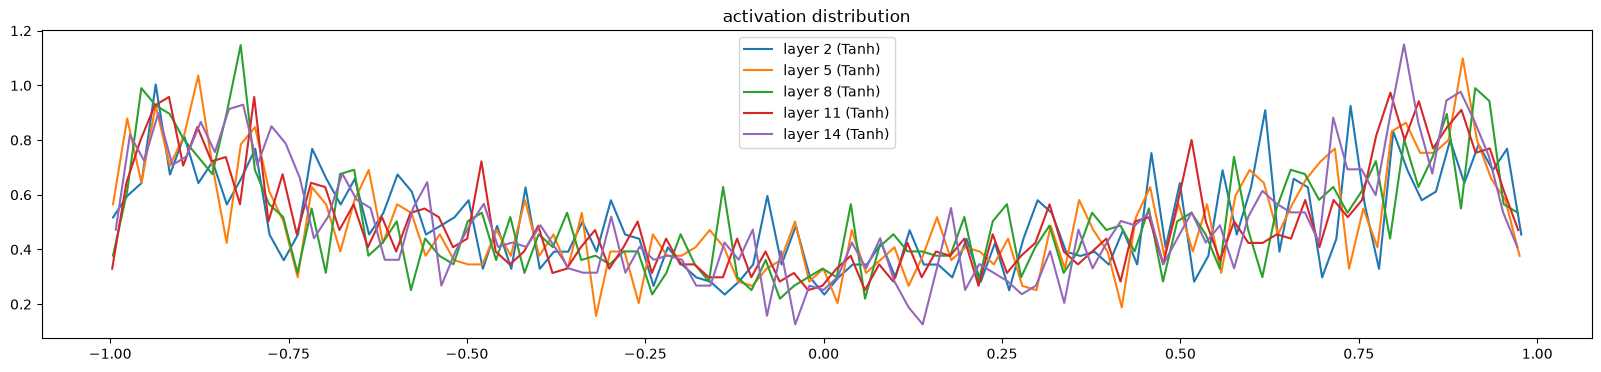

In [250]:
# visualize histograms

plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers):
    if isinstance(layer, Tanh):
        t = layer.out
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')

plt.legend(legends)
plt.title('activation distribution')
plt.show()

layer 2 (      Tanh): mean -0.000000, std 3.594962e-03
layer 5 (      Tanh): mean +0.000000, std 3.227648e-03
layer 8 (      Tanh): mean -0.000000, std 2.865107e-03
layer 11 (      Tanh): mean -0.000000, std 2.570376e-03
layer 14 (      Tanh): mean +0.000020, std 2.118546e-03


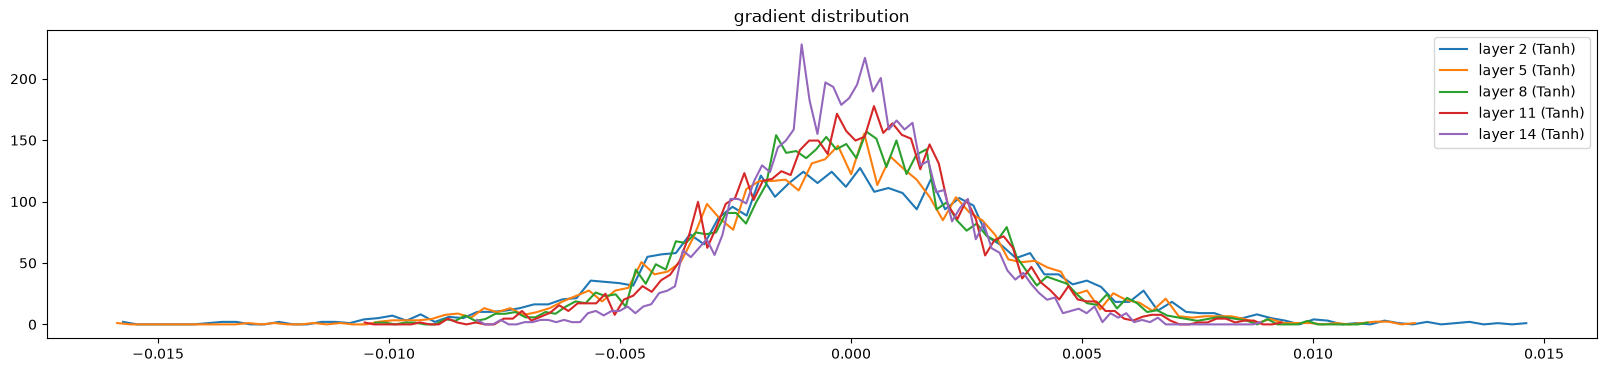

In [251]:
# visualize histograms

plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers):
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')

plt.legend(legends)
plt.title('gradient distribution')
plt.show()

weight   (27, 10) | mean +0.000000 | std 8.404450e-03 | grad:data ration 8.394152e-03
weight  (30, 100) | mean +0.000148 | std 7.077935e-03 | grad:data ration 2.261274e-02
weight (100, 100) | mean -0.000001 | std 6.137874e-03 | grad:data ration 3.659356e-02
weight (100, 100) | mean +0.000068 | std 5.360197e-03 | grad:data ration 3.172627e-02
weight (100, 100) | mean -0.000001 | std 4.970150e-03 | grad:data ration 2.958607e-02
weight (100, 100) | mean +0.000041 | std 3.891885e-03 | grad:data ration 2.319133e-02
weight  (100, 27) | mean +0.000000 | std 2.018932e-02 | grad:data ration 3.179000e-01


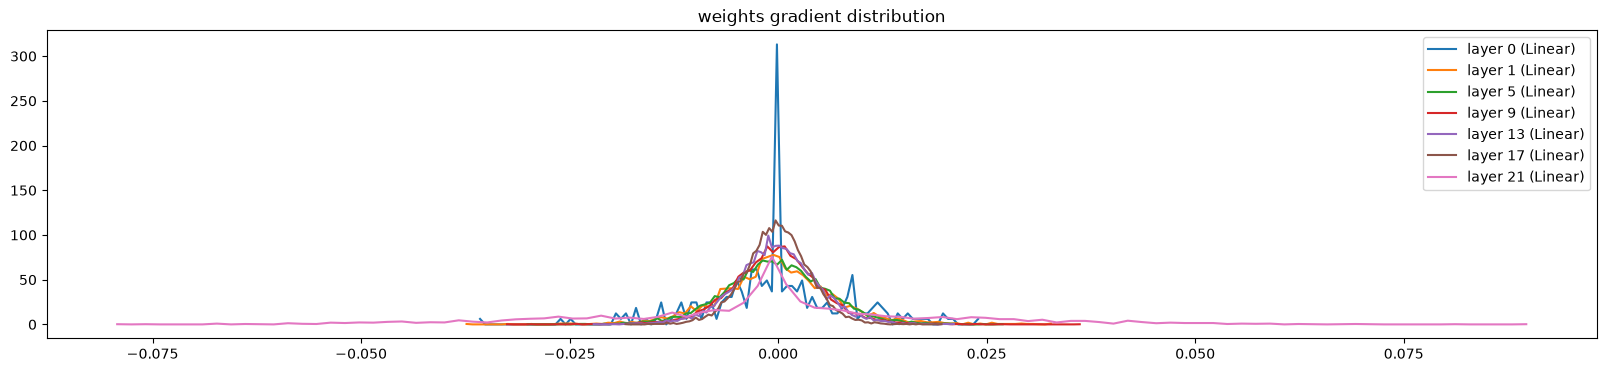

In [252]:
# visualize histograms

plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2 :
        print('weight %10s | mean %+f | std %e | grad:data ration %e' % (tuple(p.shape), t.mean(), t.std(), t.std()/p.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')

plt.legend(legends)
plt.title('weights gradient distribution')
plt.show()

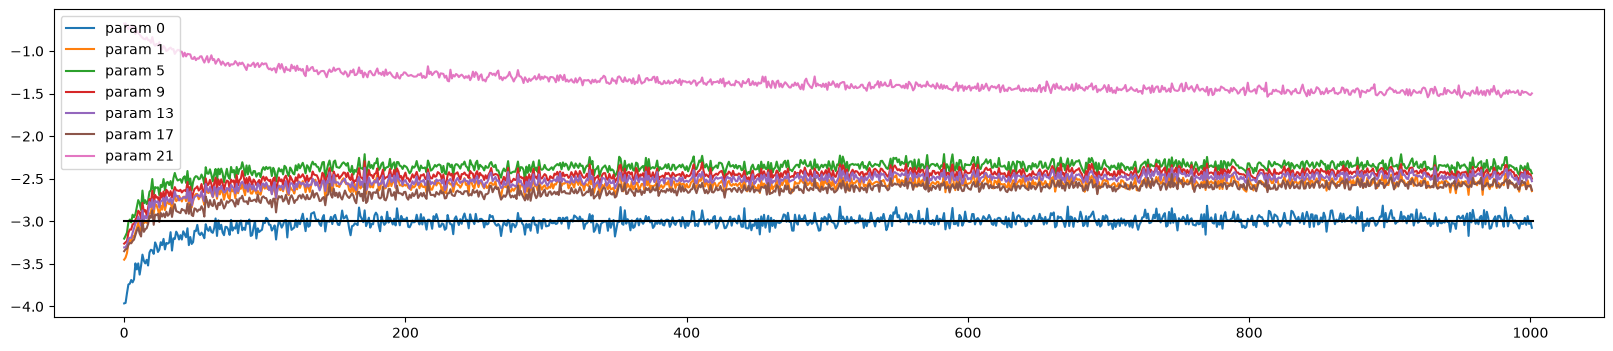

: 

In [ ]:
plt.figure(figsize=(20,4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2 :
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append('param %d' % i)

plt.plot([0, len(ud)], [-3, -3], 'k')
plt.legend(legends)